# Fitting the asset correlation to charge-off rates: maximum likelihood, profile intervals and a tail back-test

**Question:** How strongly do the defaults of each US loan type move together, how well can 22 years of charge-off rates pin that correlation down, and does the fitted model survive the years that follow?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the Vasicek loss distribution of a large portfolio)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- write the likelihood of a series of yearly loss rates under the one-factor model, and fit the PD and the asset correlation by maximum likelihood with the engine;
- fit the same two numbers by the method of moments, and say why the two estimates of the correlation differ;
- measure the uncertainty of the correlation with a profile-likelihood interval and with a parametric bootstrap, and read a profile curve;
- turn each observed year into an implied systematic factor, the credit-cycle index of the fit;
- back-test the fitted distribution on the six years after the fit window, and say what a validator concludes for each of the five loan types of US banks;
- compare the fitted correlation with the regulatory IRB correlation of the nearest asset class.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Names of the validation lights
LIGHTS = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The five loan-type files of case C10, one per column of the Federal Reserve's charge-off table `chgallsa` (https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm; public domain, licence class `mirror-allowed`): commercial and industrial loans, commercial real estate, residential real estate, credit cards and other consumer loans of all US commercial banks, 1985 to 2012. The fit window is 1985 to 2006 and the evaluation window 2007 to 2012. In each file:

- `outputs.annual_rates` holds one row per year with the loss rate, or `null` and the reason when the Board's table has no value for that loan type; a missing year is excluded and counted, never interpolated;
- `outputs.fit` holds the committed fits, `outputs.profile_likelihood` the committed profile curve, `outputs.backtest` the committed back-test and `outputs.irb_reference` the regulatory comparison.

The next cell loads the five files and counts, for each loan type, the years that have a rate in each window.

In [2]:
# Load the five artifacts and count the years with a rate in each window
NAMES = {
    "commercial-industrial": "Commercial and industrial",
    "commercial-real-estate": "Commercial real estate",
    "residential": "Residential real estate",
    "credit-cards": "Credit cards",
    "other-consumer": "Other consumer",
}
docs = {k: json.loads((ROOT / "data" / "derived" / "C10" / f"{k}.json").read_text(encoding="utf-8")) for k in NAMES}


def rates_of(key, window):
    """Yearly loss rates of a loan type in a window, NaN where the Board has none"""
    rows = docs[key]["outputs"]["annual_rates"]
    return np.array([np.nan if r["loss_rate"] is None else r["loss_rate"] for r in rows if r["window"] == window])


for key, label in NAMES.items():
    n_fit = int(np.isfinite(rates_of(key, "fit")).sum())
    n_eval = int(np.isfinite(rates_of(key, "evaluation")).sum())
    print(f"{label:28s} fit years: {n_fit:3d} | evaluation years: {n_eval:3d}")

Commercial and industrial    fit years:  22 | evaluation years:   6
Commercial real estate       fit years:  16 | evaluation years:   6
Residential real estate      fit years:  16 | evaluation years:   6
Credit cards                 fit years:  22 | evaluation years:   6
Other consumer               fit years:  22 | evaluation years:   6


## Method

### Step 1: the likelihood and the maximum-likelihood fit

Under the one-factor model the yearly loss rate $x_t$ of a very large portfolio is $p(Z_t)$ with $Z_t$ standard normal, so $x_t$ has the large-portfolio density (the derivative of the distribution function of notebook 01; Vasicek, 2002, and Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8):

$$f(x;\mathrm{PD},\rho) = \sqrt{\frac{1-\rho}{\rho}}\; \exp\!\left(\tfrac12\,\Phi^{-1}(x)^2 - \frac{\left(\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(\mathrm{PD})\right)^2}{2\rho}\right)$$

Taking the years as independent, the log-likelihood of a series is $\ell(\mathrm{PD},\rho)=\sum_t \ln f(x_t;\mathrm{PD},\rho)$, and the estimate is the pair that maximises it. The engine's `log_likelihood` evaluates it and `fit_ml` maximises it (a Nelder-Mead search on the logit scale from a fixed start, so the result is deterministic). The next cell takes the 22 fit-window rates of the commercial and industrial loans, fits them, and scans the log-likelihood in the correlation at the fitted PD.

In [3]:
# Fit by maximum likelihood and scan the likelihood in the correlation
from riskvalidation.portfolio.asrf_fit import fit_ml, log_likelihood

ci = docs["commercial-industrial"]["outputs"]
rows = ci["annual_rates"]
fit_rates = rates_of("commercial-industrial", "fit")
eval_rates = rates_of("commercial-industrial", "evaluation")
eval_years = [r["year"] for r in rows if r["window"] == "evaluation"]

est = fit_ml(fit_rates)
print("years used:", est.n_years, "| missing:", est.n_missing, "| converged:", est.converged)
print("PD:", round(est.pd, 6), "| rho:", round(est.rho, 6))
print("log-likelihood:", round(est.log_likelihood, 4))

rho_scan = np.linspace(0.01, 0.30, 59)
ll_scan = np.array([log_likelihood(fit_rates, est.pd, r) for r in rho_scan])
print("best rho on the grid:", round(float(rho_scan[ll_scan.argmax()]), 3))

years used: 22 | missing: 0 | converged: True
PD: 0.009105 | rho: 0.063677
log-likelihood: 84.8232
best rho on the grid: 0.065


The log-likelihood is a curve in $\rho$ with one peak, and the peak is the estimate. Its width is the information the 22 years carry about the correlation: a flat top means the data barely distinguish neighbouring values. The next cell draws it.

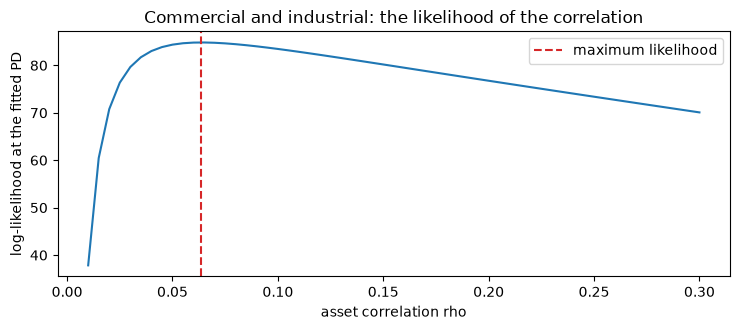

In [4]:
# Draw the log-likelihood in the correlation at the fitted PD
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(rho_scan, ll_scan, color="tab:blue")
ax.axvline(est.rho, color="tab:red", linestyle="--", label="maximum likelihood")
ax.set_xlabel("asset correlation rho")
ax.set_ylabel("log-likelihood at the fitted PD")
ax.set_title("Commercial and industrial: the likelihood of the correlation")
ax.legend()
fig.tight_layout()
plt.show()

The curve has one clear peak and the peak is the estimate, a correlation of about 0.064 at the fitted PD. On the left the likelihood drops quickly, because a correlation near zero cannot explain years as different as 1985 and 2009; on the right it falls much more slowly, so the data barely distinguish a correlation of 0.10 from 0.12. That asymmetry is the first sign that the interval of the next steps will be longer on the right than on the left. The picture holds the PD fixed, so it shows the correlation alone and not the joint uncertainty of the two parameters.

### Step 2: the method of moments, an alternative that disagrees

A simpler estimator matches two moments. The mean of the loss rate is the PD, and the second moment of the large-portfolio default fraction is the probability that two obligors default together, $E[p(Z)^2]$ (the dossier's result, dossier 04 C.4). The estimate is the PD equal to the mean of the rates and the correlation that makes $E[p(Z)^2]$ equal the mean of the squared rates. The engine's `fit_moments` solves it by root-finding, and raises an error rather than returning a zero when the rates show no excess dispersion. The next cell fits both estimators and evaluates the likelihood at each, so the two can be compared on the same scale.

In [5]:
# Fit by moments and evaluate the likelihood at both estimates
from riskvalidation.portfolio.asrf_fit import fit_moments

mom = fit_moments(fit_rates)
print("moments: PD", round(mom.pd, 6), "| rho", round(mom.rho, 6))
print("mean of the rates:", round(float(fit_rates.mean()), 6))
print(f"{'':22s} rho      log-likelihood")
print(f"{'maximum likelihood':22s} {est.rho:.4f}   {est.log_likelihood:.4f}")
print(f"{'moments':22s} {mom.rho:.4f}   {log_likelihood(fit_rates, mom.pd, mom.rho):.4f}")

moments: PD 0.008972 | rho 0.042594
mean of the rates: 0.008972
                       rho      log-likelihood
maximum likelihood     0.0637   84.8232
moments                0.0426   83.5628


### Step 3: the profile likelihood and its interval

A point estimate of $\rho$ says nothing about how well 22 years pin it down. The **profile log-likelihood** fixes $\rho$ at each value of a grid, maximises over the PD, and records the maximum: $\ell_p(\rho)=\max_{\mathrm{PD}}\ell(\mathrm{PD},\rho)$. The likelihood-ratio interval keeps the values of $\rho$ whose profile is within $\chi^2_{1,0.95}/2 = 1.9207$ of the top. The engine's `profile_likelihood` evaluates the curve on a grid and `profile_interval` finds the endpoints. The next cell evaluates the profile on a grid of 42 correlations and finds the 95% interval of the correlation and of the PD.

In [6]:
# Evaluate the profile log-likelihood on a grid and find the likelihood-ratio interval
from scipy import stats

from riskvalidation.portfolio.asrf_fit import profile_interval, profile_likelihood

grid = np.linspace(0.015, 0.25, 42)
ll_profile, pd_at_rho = profile_likelihood(fit_rates, grid)
drop = stats.chi2.ppf(0.95, 1) / 2
print("drop below the top for 95%:", round(float(drop), 4))

interval = profile_interval(fit_rates, 0.95)
print("rho 95% interval:", tuple(round(v, 4) for v in interval["rho"]))
print("PD 95% interval:", tuple(round(v, 5) for v in interval["pd"]))

drop below the top for 95%: 1.9207
rho 95% interval: (0.0382, 0.1158)
PD 95% interval: (0.0068, 0.01297)


The picture shows why the interval is asymmetric: the profile falls slowly to the right, so high correlations stay plausible long after low ones are excluded. The next cell draws the profile, the cutoff, the interval and the moments estimate.

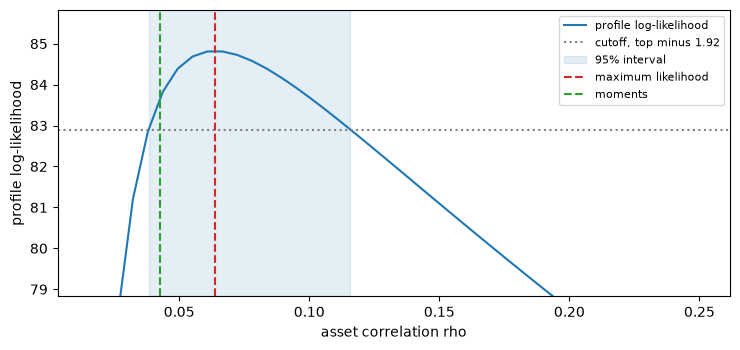

In [7]:
# Draw the profile log-likelihood with its cutoff, the interval and the moments estimate
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(grid, ll_profile, color="tab:blue", label="profile log-likelihood")
ax.axhline(est.log_likelihood - drop, color="gray", linestyle=":", label="cutoff, top minus 1.92")
ax.axvspan(*interval["rho"], color="tab:blue", alpha=0.12, label="95% interval")
ax.axvline(est.rho, color="tab:red", linestyle="--", label="maximum likelihood")
ax.axvline(mom.rho, color="tab:green", linestyle="--", label="moments")
ax.set_xlabel("asset correlation rho")
ax.set_ylabel("profile log-likelihood")
ax.set_ylim(est.log_likelihood - 6, est.log_likelihood + 1)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The profile makes the two estimators comparable on one axis. The blue band is the 95% interval, the red line the maximum-likelihood correlation and the green line the moments estimate, which falls inside the band but on its lower shoulder, where the profile is already well below the top. The band is not centred on the red line: it reaches much further to the right, so the data allow a correlation of 0.11 or more far more easily than one under 0.04. A capital figure that scales with the correlation therefore has more room to be too low than too high. The profile shows nothing about the dependence between consecutive years, which the factors of step 5 reveal.

### Step 4: a parametric bootstrap for the moments estimate

The method of moments has no likelihood to profile, so its uncertainty comes from a **parametric bootstrap**: take the fitted $(\mathrm{PD},\rho)$, draw 22 new systematic factors $z_t \sim N(0,1)$, turn each into a loss rate $p(z_t)$, refit, and repeat. The 2.5% and 97.5% percentiles of the refitted values are the interval. The engine's `bootstrap_interval` does this with a seeded generator, so it is reproducible; a refit that fails is dropped and counted. The next cell runs 500 seeded refits and prints the interval of the correlation and of the PD.

In [8]:
# Run the seeded parametric resampling of the moments estimate
from riskvalidation.portfolio.asrf_fit import bootstrap_interval

boot = bootstrap_interval(fit_rates, "moments", 500, 4007, 0.95)
print("refits:", boot.n_boot, "| dropped:", boot.n_dropped)
print("rho interval by resampling:", tuple(round(v, 4) for v in boot["rho"]))
print("PD interval by resampling:", tuple(round(v, 5) for v in boot["pd"]))
inside = interval["rho"][0] <= mom.rho <= interval["rho"][1]
print("moments estimate inside the likelihood interval:", bool(inside))

refits: 500 | dropped: 0
rho interval by resampling: (0.0189, 0.0755)
PD interval by resampling: (0.00727, 0.01136)
moments estimate inside the likelihood interval: True


### Step 5: the implied systematic factor of each year

Given the fitted $(\mathrm{PD},\rho)$, each yearly loss rate implies the value of the systematic factor that would have produced it, the inverse of the conditional PD of notebook 01:

$$\hat z_t = \frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{1-\rho}\,\Phi^{-1}(x_t)}{\sqrt{\rho}}$$

The series $\hat z_t$ is the credit-cycle index of the fit: negative in bad years, positive in good ones (Belkin, Suchower and Forest, 1998; a derivation from the model here, not a quoted equation). If the model were right, the $\hat z_t$ would look like draws from a standard normal. The engine's `implied_factors` computes the whole series and leaves NaN where a year is missing. The next cell computes it for the 28 years and prints its mean, its spread, its lowest year and its lag-1 autocorrelation.

In [9]:
# Compute the implied factor of the 28 years and summarise it
from riskvalidation.portfolio.asrf_fit import implied_factors

all_rates = np.array([np.nan if r["loss_rate"] is None else r["loss_rate"] for r in rows])
all_years = np.array([r["year"] for r in rows])
in_fit = np.array([r["window"] == "fit" for r in rows])
z_hat = implied_factors(all_rates, est.pd, est.rho)

print("mean and standard deviation of the fit-window factors:")
print("   ", round(float(z_hat[in_fit].mean()), 3), round(float(z_hat[in_fit].std(ddof=1)), 3))
print("lowest factor:", int(all_years[np.nanargmin(z_hat)]), round(float(np.nanmin(z_hat)), 3))
print("autocorrelation at lag 1 of the 28 factors:", round(float(np.corrcoef(z_hat[:-1], z_hat[1:])[0, 1]), 3))

mean and standard deviation of the fit-window factors:
    -0.0 1.024
lowest factor: 2009 -1.708
autocorrelation at lag 1 of the 28 factors: 0.761


The next cell draws the 28 implied factors as bars, coloured by window.

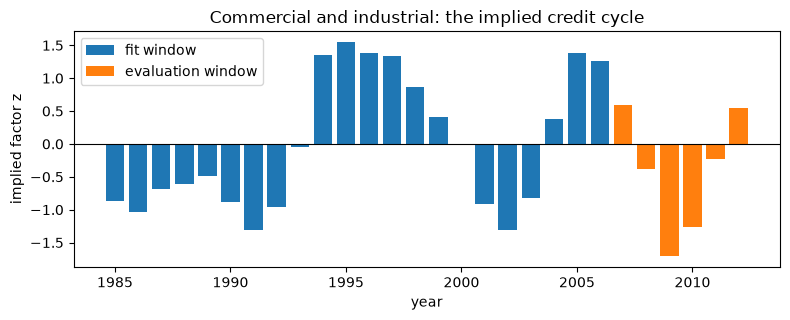

In [10]:
# Draw the implied factors with the two windows marked
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(all_years[in_fit], z_hat[in_fit], color="tab:blue", label="fit window")
ax.bar(all_years[~in_fit], z_hat[~in_fit], color="tab:orange", label="evaluation window")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("year")
ax.set_ylabel("implied factor z")
ax.set_title("Commercial and industrial: the implied credit cycle")
ax.legend()
fig.tight_layout()
plt.show()

The bars are the credit cycle the model reads out of the loss rates. Negative runs are bad times and they come in blocks: 1985 to 1992, 2001 to 2003 and 2008 to 2011, with 2009 the lowest. Positive runs fill 1994 to 1998 and 2004 to 2007. If the factors were independent draws the bars would flip sign at random, and they plainly do not, which the lag-1 autocorrelation above quantifies. The likelihood treats the years as independent, so its interval is conditional on a property the data contradict; the figure cannot say by how much the interval is too narrow, only that it is.

### Step 6: a tail back-test on the six years after the fit

A fitted distribution makes a prediction: in $n$ future years, the number of years above its $q$-quantile is Binomial$(n, 1-q)$. The engine's `tail_backtest` counts the evaluation-window years above the fitted 95%, 99% and 99.9% quantiles and reports the upper binomial tail $P(X \ge \text{observed})$ as its p-value, at the primary level of 99%; it is a Contraste internal gate with the light green from a p-value of 0.05 and red below 0.01, not a regulatory threshold. With six years the test has little power, so the counts are shown beside the p-value. The next cell runs it on the commercial and industrial loans and prints the counts at the three levels.

In [11]:
# Back-test the commercial and industrial fit on 2007 to 2012
from riskvalidation.validation.portfolio import tail_backtest

levels = (0.95, 0.99, 0.999)
result = tail_backtest(eval_rates, est.pd, est.rho, levels=levels, primary_level=0.99, model_id="m-lhp")
print("light:", LIGHTS[result.light.value], "| p-value:", round(result.p_value, 6))
print("observed at 99%:", int(result.statistic), "| expected:", round(result.metric, 4))
print(f"{'q':>6s} {'fitted quantile':>20s} {'expected':>10s} {'observed':>10s} {'p':>8s}")
for row in result.extras["levels"]:
    head = f"{row['level']:6.3f} {row['fitted_quantile']:20.5f}"
    print(head, f"{row['expected']:10.3f} {row['observed']:10d} {row['p_value']:8.4f}")

light: green | p-value: 1.0
observed at 99%: 0 | expected: 0.06
     q      fitted quantile   expected   observed        p
 0.950              0.02214      0.300          1   0.2649
 0.990              0.03335      0.060          0   1.0000
 0.999              0.05109      0.006          0   1.0000


The next cell draws the six evaluation years against the fitted 95%, 99% and 99.9% quantiles.

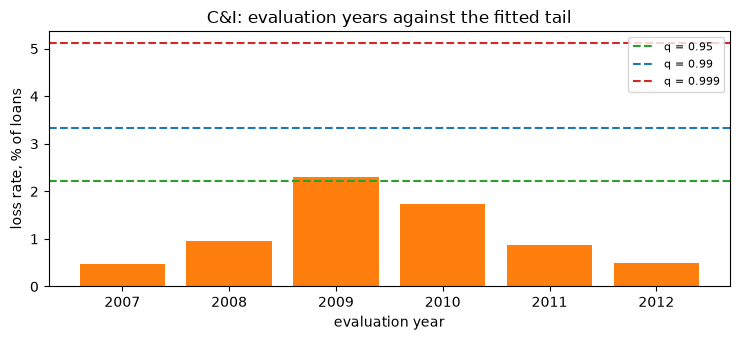

In [12]:
# Draw the evaluation years against the fitted quantiles
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar([str(y) for y in eval_years], 100 * eval_rates, color="tab:orange")
for row, color in zip(result.extras["levels"], ("tab:green", "tab:blue", "tab:red")):
    ax.axhline(100 * row["fitted_quantile"], color=color, linestyle="--", label=f"q = {row['level']}")
ax.set_xlabel("evaluation year")
ax.set_ylabel("loss rate, % of loans")
ax.set_title("C&I: evaluation years against the fitted tail")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Only 2009 crosses a dashed line, and only the 95% one: the worst year of the whole series stays under the fitted 99% quantile. The bars of 2007, 2008, 2011 and 2012 stay under 1% of loans, well below every line, and 2010 at 1.74% is under the 95% line too. That is what the model predicts for a window of six years, which is why the test is green, but the test has little power: it needs two years above the 99% line to turn red, and a model with a quantile far too low would still pass if the six years happened to be mild. The figure shows the commercial and industrial loans only; the retail types of the next cells behave differently.

The same pipeline of steps runs on each loan type. The next cell fits each type's own fit window, measures the profile interval, back-tests the evaluation window, and recomputes the regulatory IRB correlation of the nearest asset class with the engine's `capital_requirement` (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm; the class is the closest regulatory class, not a claim that the Board's series is that class). It prints one row per loan type: the fitted correlation and its interval, the IRB correlation, the years above the fitted 99% quantile and the light.

In [13]:
# Fit, profile and back-test the five loan types against the IRB correlation
from riskvalidation.regulatory.irb import capital_requirement

summary = {}
for key in NAMES:
    fit_k = rates_of(key, "fit")
    fitted = fit_ml(fit_k)
    band = profile_interval(fit_k, 0.95)["rho"]
    evaluation = rates_of(key, "evaluation")
    test = tail_backtest(evaluation, fitted.pd, fitted.rho, levels=levels, primary_level=0.99, model_id="m-lhp")
    asset_class = docs[key]["outputs"]["irb_reference"]["asset_class"]
    extra = {} if asset_class in ("residential_mortgage", "qrre", "other_retail") else {"maturity": 2.5}
    irb = capital_requirement(asset_class, fitted.pd, 0.45, regime="basel3", **extra)
    summary[key] = (fitted, band, test, irb)

print(f"{'loan type':26s} {'years':>5s} {'rho':>7s} {'rho IRB':>8s} {'>q99':>5s} {'p':>9s} light")
for key, label in NAMES.items():
    fitted, band, test, irb = summary[key]
    head = f"{label:26s} {fitted.n_years:5d} {fitted.rho:7.4f} {irb.correlation:8.4f}"
    print(head, f"{int(test.statistic):5d} {test.p_value:9.2e}", LIGHTS[test.light.value])

loan type                  years     rho  rho IRB  >q99         p light
Commercial and industrial     22  0.0637   0.1961     0  1.00e+00 green
Commercial real estate        16  0.2384   0.2647     0  1.00e+00 green
Residential real estate       16  0.0129   0.1500     5  5.95e-10 red
Credit cards                  22  0.0127   0.0400     2  1.46e-03 red
Other consumer                22  0.0109   0.1224     3  1.96e-05 red


The next cell draws, for each loan type, the fitted correlation with its 95% interval and the regulatory IRB correlation of the nearest asset class.

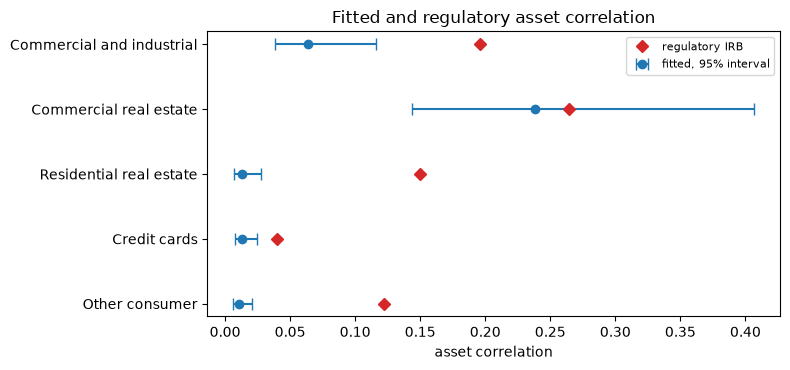

In [14]:
# Draw the fitted correlation with its interval beside the IRB correlation
rho_fit = np.array([summary[k][0].rho for k in NAMES])
low = rho_fit - np.array([summary[k][1][0] for k in NAMES])
high = np.array([summary[k][1][1] for k in NAMES]) - rho_fit
rho_irb = np.array([summary[k][3].correlation for k in NAMES])
position = np.arange(len(NAMES))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(rho_fit, position, xerr=[low, high], fmt="o", color="tab:blue", capsize=4,
            label="fitted, 95% interval")
ax.plot(rho_irb, position, "D", color="tab:red", label="regulatory IRB")
ax.set_yticks(position, list(NAMES.values()))
ax.invert_yaxis()
ax.set_xlabel("asset correlation")
ax.set_title("Fitted and regulatory asset correlation")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The blue dots with their bars are what each series of yearly loss rates supports; the red diamonds are the supervisory values. Four of the five diamonds lie far to the right of the whole blue bar, which says the fitted correlations are not merely a little below the regulatory ones but outside the range the data allow. Commercial real estate is the exception: its bar is wide, from 0.14 to 0.41, and the regulatory value falls inside it. The widths differ because the real-estate series has only 16 usable years and a much stronger cycle. The comparison measures a gap, not its cause, since the IRB values are calibrations for large internationally active banks, not estimates from this table.

The regulatory formula and the fit are two answers to a different question, so we compare their capital, not only their correlations. The committed `irb_reference` block holds, per loan type, the large-portfolio capital at 99.9% with the fitted correlation and the IRB capital $K$, both at the same PD, LGD of 45% and maturity adjustment; their ratio is the committed number the executive view quotes. The next cell recomputes the fitted capital from the fitted correlation and the IRB maturity adjustment, and divides it by the IRB capital.

In [15]:
# Compute the fitted capital at 99.9% and its ratio to the IRB capital
from riskvalidation.engines.vasicek import lhp_quantile

ratios = {}
print(f"{'loan type':26s} {'fitted capital':>18s} {'K IRB':>8s} {'ratio':>8s}")
for key, label in NAMES.items():
    fitted, _, _, irb = summary[key]
    tail = float(lhp_quantile(0.999, fitted.pd, fitted.rho)) - fitted.pd
    capital = 0.45 * tail * (irb.maturity_adjustment or 1.0)
    ratios[key] = capital / float(irb.k)
    print(f"{label:26s} {capital:18.5f} {float(irb.k):8.5f} {ratios[key]:8.3f}")

loan type                      fitted capital    K IRB    ratio
Commercial and industrial             0.02397  0.07137    0.336
Commercial real estate                0.05870  0.06679    0.879
Residential real estate               0.00115  0.01102    0.104
Credit cards                          0.01835  0.03917    0.468
Other consumer                        0.00529  0.03622    0.146


The next cell draws the ratio of the fitted capital to the IRB capital, one bar per loan type, with the equal-capital line at 1.

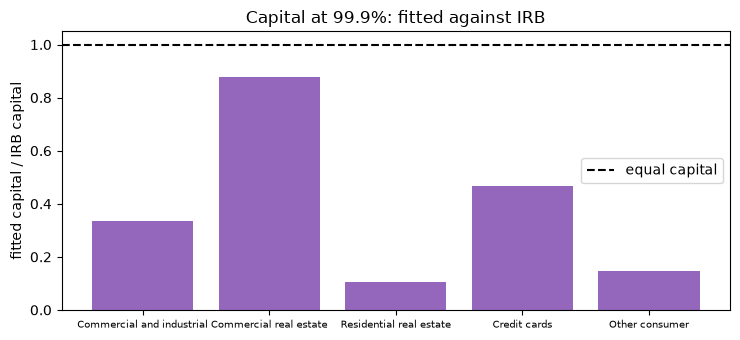

In [16]:
# Draw the ratio of the fitted capital to the IRB capital
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(list(NAMES.values()), [ratios[k] for k in NAMES], color="tab:purple")
ax.axhline(1.0, color="black", linestyle="--", label="equal capital")
ax.set_ylabel("fitted capital / IRB capital")
ax.set_title("Capital at 99.9%: fitted against IRB")
ax.tick_params(axis="x", labelsize=7)
ax.legend()
fig.tight_layout()
plt.show()

Every bar is below the dashed line, so at the same PD, LGD of 45% and maturity adjustment the fitted correlation would ask for less capital than the IRB formula for all five loan types. The shortfall is a factor of three for commercial and industrial loans and nearly ten for residential real estate, while commercial real estate is close to parity. The ratio mixes two effects, a lower correlation and the shape of the loss quantile, and the bars say nothing about whether the supervisory formula is too conservative or the benign fit window too kind: the back-test of the retail types points to the second reading for them.

## Results

**Answer:** the defaults of commercial and industrial loans move together with an asset correlation of 0.0637 and a PD of 0.91%, but 22 years of rates only fix the correlation within a 95% interval of 0.0382 to 0.1158; the fit passes the 2007 to 2012 test for that loan type (no year above the 99% quantile) and fails it for the three retail types, and its capital is a third of the IRB capital (ratio 0.336).

- **The maximum-likelihood fit.** On the 22 fit-window years of the commercial and industrial loans, maximum likelihood gives a PD of 0.91% and a correlation of 0.0637, with a log-likelihood of 84.82 and a converged search. The log-likelihood in the correlation has one peak, steeper on the left than on the right.
- **The two estimators disagree, and the likelihood says which fits better.** The method of moments gives a correlation of 0.0426, against 0.0637 for maximum likelihood; the log-likelihood is 83.56 at the moments estimate and 84.82 at the maximum. The moments estimate lies inside the likelihood interval, so the data do not exclude it, but it is the less efficient of the two.
- **Twenty-two years pin the correlation down only loosely.** The likelihood-ratio interval is 0.0382 to 0.1158, a range of a factor of three, and it is asymmetric: the profile falls slowly to the right. The resampling interval of the moments estimate, 0.0189 to 0.0755, comes from 500 seeded refits and none was dropped. Any capital figure that depends on the correlation inherits this range.
- **The credit cycle is persistent, and the model assumes it is not.** The implied factors of the fit window have mean 0.0 and standard deviation 1.02, as a standard normal would, and the lowest is 2009 at -1.71. But the lag-1 autocorrelation of the 28 factors is 0.76: a bad year tends to be followed by another. The likelihood treats the years as independent, so its interval is conditional on that assumption and probably optimistic.
- **The back-test separates the loan types.** For commercial and industrial loans no evaluation year is above the fitted 99% quantile (0.06 expected) and one is above the 95% quantile (2009, 0.30 expected): green, p = 1.0. Commercial real estate is also green. Residential real estate has 5 of 6 years above the 99% quantile (p = 6e-10), credit cards 2 of 6 (p = 0.0015) and other consumer 3 of 6 (p = 2e-5): all red. The three retail types were fitted on a window without the 2007 to 2009 crisis (residential also has only 16 usable years, the Board's table having no value before 1991), and the evaluation window is that crisis. The test does not say the one-factor model is wrong; it says a fit on a benign window under-states the tail it later meets.
- **The fitted correlation is below the regulatory one for all five types, and far below it for four.** Commercial and industrial: 0.0637 against the IRB 0.1961; residential: 0.0129 against 0.15; credit cards: 0.0127 against 0.04; other consumer: 0.0109 against 0.1224. Commercial real estate is the close one, 0.2384 against 0.2647. The fitted-to-IRB capital ratios are 0.336, 0.104, 0.468, 0.146 and 0.879. The comparison measures the size of the gap and not its cause: the IRB correlations are supervisory calibrations, and nothing here says they are wrong.

What this notebook does not show: how well each estimator recovers a known correlation (the size and power study, notebooks 06 and 08), what the correlation implies for a finite portfolio (notebooks 03 to 05), or how the interval changes when the years are dependent.

## Summary

- The likelihood of yearly loss rates under the one-factor model is the sum of the log large-portfolio densities; `fit_ml` maximises it and `fit_moments` matches the first two moments, and the two differ.
- The uncertainty of the correlation is a profile-likelihood interval (`profile_likelihood`, `profile_interval`) or a seeded parametric bootstrap (`bootstrap_interval`); with 22 years it spans a factor of three.
- `implied_factors` turns each year into the credit-cycle index of the fit; its strong autocorrelation says the independent-years assumption is optimistic.
- `tail_backtest` counts evaluation years above the fitted quantiles against a binomial; it passes commercial loans and fails the retail types fitted on a benign window.
- The fitted correlation is below the IRB correlation for all five types, and the capital ratio to IRB is the number to read, with the interval beside it.

**What to try next.** Change the fit window to 1985 to 2009 for the retail types and rerun the back-test on 2010 to 2012. Then open notebook 03, where the fitted correlation drives a Monte Carlo of a finite portfolio.

## References

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Belkin, B., Suchower, S. and Forest, L. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, as cited by the engine's `engines.vasicek` module.
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections C.4 (the Vasicek model and the moment equation) and H.1 (the loss measures).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.